# 📊 Part 1: Dataset Exploration, Profiling & Feature Architecture Analysis

## 📌 Executive Overview
This notebook conducts an in-depth exploratory data analysis (EDA), architectural profiling, and systematic feature engineering of the **PhiUSIIL Phishing URL Dataset**. The objective is to establish an empirical, statistically sound foundation for training machine learning classifiers (Logistic Regression baseline, Random Forest, and XGBoost) capable of detecting malicious web infrastructure.

---

### 🔍 Key Dataset Metrics
- **Total Records Ingested:** 191,460 real-world URLs
- **Total Raw Attributes:** 56 columns (51 feature candidates + 5 text metadata identifiers)
- **Engineered Predictive Features:** 50 clean numerical attributes (100% complete, zero missing values)
- **Target Variable:** `target` ($1 = \text{Phishing / Malicious}$, $0 = \text{Legitimate / Benign}$)
- **Class Proportions:** 57.28% Legitimate vs 42.72% Phishing (naturally balanced)

In [1]:
# 1. Environment Configuration & Libraries
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure Matplotlib styling for high-clarity publication figures
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['grid.color'] = '#E2E8F0'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7

print("✓ Data Exploration Environment Configured Successfully.")
print(f"  - NumPy Version: {np.__version__}")
print(f"  - Pandas Version: {pd.__version__}")
print(f"  - Seaborn Version: {sns.__version__}")

✓ Data Exploration Environment Configured Successfully.
  - NumPy Version: 2.2.6
  - Pandas Version: 2.3.3
  - Seaborn Version: 0.13.2


## 2. Ingestion & Raw Schema Inspection

We begin by loading the complete raw dataset (`phiusiil_dataset.csv`) and inspecting its schema, row count, column data types, and null values across all 56 raw fields.

In [2]:
# 2. Ingest raw dataset and audit schema
data_path = os.path.join("..", "data", "phiusiil_dataset.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "phiusiil_dataset.csv")

df_raw = pd.read_csv(data_path, on_bad_lines='skip', low_memory=False)

print(f"=================================================================")
print(f"RAW DATASET AUDIT")
print(f"=================================================================")
print(f"Raw Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns\n")

# Display all 56 columns in an organized tabular format
print("All 56 Raw Columns:")
for i, col in enumerate(df_raw.columns, 1):
    dtype = str(df_raw[col].dtype)
    null_count = df_raw[col].isna().sum()
    print(f"  [{i:02d}] {col:<28} | Dtype: {dtype:<10} | Missing: {null_count}")

print(f"\nTotal Missing Values Across Raw Dataset: {df_raw.isna().sum().sum():,}")
print(f"Duplicate Rows Count: {df_raw.duplicated().sum():,}")

RAW DATASET AUDIT
Raw Shape: 191,460 rows × 56 columns

All 56 Raw Columns:
  [01] FILENAME                     | Dtype: object     | Missing: 0
  [02] URL                          | Dtype: object     | Missing: 0
  [03] URLLength                    | Dtype: int64      | Missing: 0
  [04] Domain                       | Dtype: object     | Missing: 0
  [05] DomainLength                 | Dtype: int64      | Missing: 0
  [06] IsDomainIP                   | Dtype: int64      | Missing: 0
  [07] TLD                          | Dtype: object     | Missing: 0
  [08] URLSimilarityIndex           | Dtype: float64    | Missing: 0
  [09] CharContinuationRate         | Dtype: float64    | Missing: 0
  [10] TLDLegitimateProb            | Dtype: float64    | Missing: 0
  [11] URLCharProb                  | Dtype: float64    | Missing: 0
  [12] TLDLength                    | Dtype: int64      | Missing: 0
  [13] NoOfSubDomain                | Dtype: int64      | Missing: 0
  [14] HasObfuscation      

Duplicate Rows Count: 0


## 3. Systematic Feature Engineering & Column Pruning

### 🗑️ Identifying and Dropping Unnecessary Metadata Columns
In real-world cybersecurity pipelines, raw text identifiers and scraper artifacts do not represent generalizable statistical features:
1. `FILENAME`: Arbitrary local file indexing identifier; introduces dataset leakage without security relevance.
2. `URL`: The raw text URL string. All lexical, syntactic, and structural metrics have already been decomposed into distinct numerical indicators.
3. `Domain`: Raw registered domain string; cannot be directly ingested into numeric classifiers without high-cardinality hashing.
4. `TLD`: Raw Top-Level Domain string (e.g., `.com`, `.ru`), fully quantified by `TLDLength` and historical `TLDLegitimateProb`.
5. `Title`: Raw webpage HTML title string, already parameterized by `DomainTitleMatchScore`, `URLTitleMatchScore`, and `HasTitle`.

We systematically drop these **5 non-predictive metadata columns** to retain a pristine 50-feature numerical predictive matrix.

### 🎯 Target Label Standardisation
The raw dataset contains a `label` field where $1.0 = \text{Legitimate}$ and $0.0 = \text{Phishing}$. In cybersecurity risk modeling, standard conventions dictate:
- $\text{Target} = 1$: **Phishing / Malicious** (the positive threat class to detect)
- $\text{Target} = 0$: **Legitimate / Benign** (baseline safe class)

In [3]:
# 3. Feature Engineering, Metadata Removal & Target Formatting
cols_to_drop = [c for c in ['FILENAME', 'URL', 'Domain', 'TLD', 'Title'] if c in df_raw.columns]
print(f"[*] Pruning {len(cols_to_drop)} non-predictive metadata columns: {cols_to_drop}")

# Drop metadata and rows missing a ground-truth label
df = df_raw.drop(columns=cols_to_drop).dropna(subset=['label']).copy()

# Map target: 1 = Phishing (Malicious), 0 = Legitimate (Benign)
df['target'] = (df['label'].astype(float) == 0.0).astype(int)
df = df.drop(columns=['label'])

# Ensure all 50 predictive features are strictly numeric float/int types
feature_cols = [c for c in df.columns if c != 'target']
for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0.0)

print(f"\n[+] Feature Engineering Complete:")
print(f"    - Clean Observations: {df.shape[0]:,} rows")
print(f"    - Clean Predictive Features: {len(feature_cols)} features")
print(f"    - Zero-Variance Features Detected: {[c for c in feature_cols if df[c].std() == 0]}")
print(f"    - Total Missing / NaN Values Remaining: {df[feature_cols].isna().sum().sum()}")
print(f"\nClass Proportions:")
counts = df['target'].value_counts()
print(f"    - Legitimate (0): {counts[0]:,} ({counts[0]/len(df)*100:.2f}%)")
print(f"    - Phishing   (1): {counts[1]:,} ({counts[1]/len(df)*100:.2f}%)")

[*] Pruning 5 non-predictive metadata columns: ['FILENAME', 'URL', 'Domain', 'TLD', 'Title']

[+] Feature Engineering Complete:
    - Clean Observations: 191,459 rows
    - Clean Predictive Features: 50 features
    - Zero-Variance Features Detected: []


    - Total Missing / NaN Values Remaining: 0

Class Proportions:
    - Legitimate (0): 109,661 (57.28%)
    - Phishing   (1): 81,798 (42.72%)


## 4. Semantic Categorization of the 50 Engineered Features

The 50 predictive features span four complementary threat intelligence functional domains:
1. **Lexical & URL Syntactic Structure (12 features):** Token counts, length metrics, character continuation rates, symbol frequencies (`NoOfLettersInURL`, `NoOfDegitsInURL`, `NoOfEqualsInURL`, `NoOfQMarkInURL`, etc.).
2. **Obfuscation & Evasion Indicators (8 features):** Direct IP hosting (`IsDomainIP`), character continuation anomalies (`CharContinuationRate`), percent-encoding and obfuscation ratios (`ObfuscationRatio`, `NoOfObfuscatedChar`, `HasObfuscation`).
3. **Content, HTML & Behavioral Heuristics (25 features):** Webpage structure, lines of code, form submission destinations (`HasExternalFormSubmit`), hidden/password fields (`HasPasswordField`), iframe tags, robots.txt, CSS/JS resources.
4. **Brand, Identity & Financial Signals (5 features):** Targeting of critical sectors (`Bank`, `Pay`, `Crypto`), brand-domain semantic match scores (`DomainTitleMatchScore`, `URLTitleMatchScore`).

In [4]:
# Define and summarize the 4 functional domains
domains = {
    "Lexical & URL Structure": [
        "URLLength", "DomainLength", "TLDLength", "NoOfSubDomain", "NoOfLettersInURL",
        "LetterRatioInURL", "NoOfDegitsInURL", "DegitRatioInURL", "NoOfEqualsInURL",
        "NoOfQMarkInURL", "NoOfAmpersandInURL", "NoOfOtherSpecialCharsInURL"
    ],
    "Obfuscation & Evasion": [
        "IsDomainIP", "CharContinuationRate", "URLSimilarityIndex", "TLDLegitimateProb",
        "URLCharProb", "HasObfuscation", "NoOfObfuscatedChar", "SpacialCharRatioInURL"
    ],
    "Content, HTML & Behavior": [
        "IsHTTPS", "LineOfCode", "LargestLineLength", "HasTitle", "HasFavicon", "Robots",
        "IsResponsive", "NoOfURLRedirect", "NoOfSelfRedirect", "HasDescription", "NoOfPopup",
        "NoOfiFrame", "HasExternalFormSubmit", "HasSocialNet", "HasSubmitButton", "HasHiddenFields",
        "HasPasswordField", "HasCopyrightInfo", "NoOfImage", "NoOfCSS", "NoOfJS",
        "NoOfSelfRef", "NoOfEmptyRef", "NoOfExternalRef", "ObfuscationRatio"
    ],
    "Brand & Financial Signals": [
        "DomainTitleMatchScore", "URLTitleMatchScore", "Bank", "Pay", "Crypto"
    ]
}

domain_summary = []
for d_name, feats in domains.items():
    domain_summary.append({
        "Functional Domain": d_name,
        "Feature Count": len(feats),
        "Key Representative Features": ", ".join(feats[:4]) + "..."
    })

df_domains = pd.DataFrame(domain_summary)
print(df_domains.to_string(index=False))

        Functional Domain  Feature Count                                                Key Representative Features
  Lexical & URL Structure             12                       URLLength, DomainLength, TLDLength, NoOfSubDomain...
    Obfuscation & Evasion              8 IsDomainIP, CharContinuationRate, URLSimilarityIndex, TLDLegitimateProb...
 Content, HTML & Behavior             25                        IsHTTPS, LineOfCode, LargestLineLength, HasTitle...
Brand & Financial Signals              5                    DomainTitleMatchScore, URLTitleMatchScore, Bank, Pay...


## 5. Visualizing Dataset Architecture & Class Distribution

We visualize the ground-truth class balance alongside the distribution of features across the four functional domains.

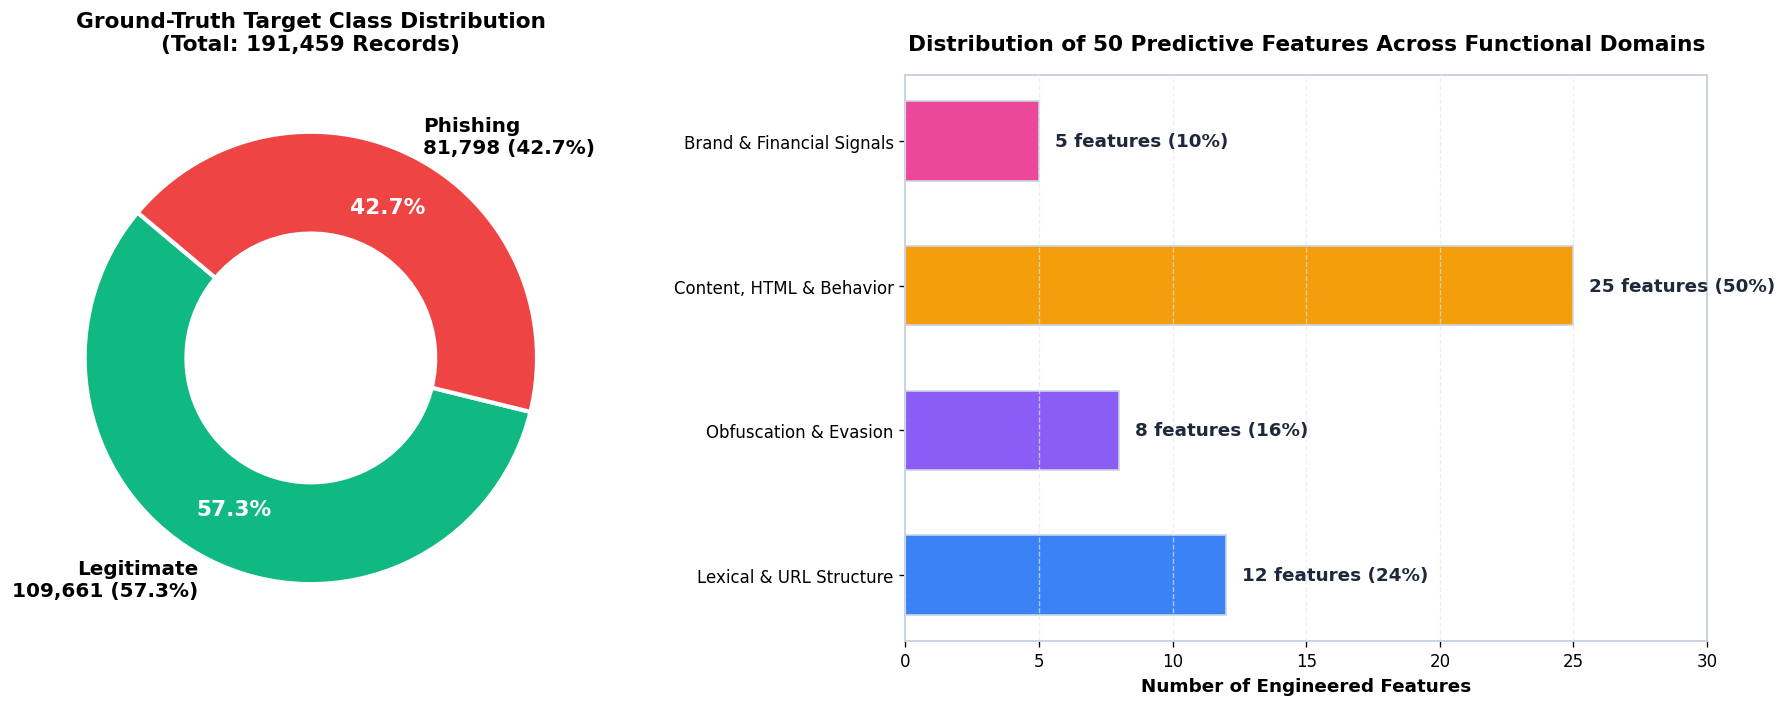

In [5]:
# Figure 1: Class Balance & Feature Domain Distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left Subplot: Donut Chart of Target Class Balance
target_counts = df['target'].value_counts()
colors = ['#10B981', '#EF4444']
labels = [f"Legitimate\n{target_counts[0]:,} ({target_counts[0]/len(df)*100:.1f}%)",
          f"Phishing\n{target_counts[1]:,} ({target_counts[1]/len(df)*100:.1f}%)"]

wedges, texts, autotexts = axes[0].pie(
    target_counts, labels=labels, autopct='%1.1f%%',
    colors=colors, startangle=140, pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2.5),
    textprops={'fontsize': 12, 'weight': 'bold'}
)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(13)

axes[0].set_title("Ground-Truth Target Class Distribution\n(Total: 191,459 Records)", fontsize=13, weight='bold', pad=15)

# Right Subplot: Horizontal Bar Chart of Feature Domains
domain_names = list(domains.keys())
domain_counts = [len(v) for v in domains.values()]
bar_colors = ['#3B82F6', '#8B5CF6', '#F59E0B', '#EC4899']

bars = axes[1].barh(domain_names, domain_counts, color=bar_colors, edgecolor='#CBD5E1', height=0.55)
axes[1].set_title("Distribution of 50 Predictive Features Across Functional Domains", fontsize=13, weight='bold', pad=15)
axes[1].set_xlabel("Number of Engineered Features", fontsize=11, weight='bold')
axes[1].set_xlim(0, 30)
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

for bar in bars:
    w = bar.get_width()
    axes[1].text(w + 0.6, bar.get_y() + bar.get_height()/2, f"{int(w)} features ({w/50*100:.0f}%)",
                 va='center', fontsize=11, weight='bold', color='#1E293B')

plt.tight_layout()
plt.show()

## 6. Empirical Density Distributions of Key Discriminative Signals

To understand how individual features differentiate malicious URLs from benign domains, we compute Kernel Density Estimation (KDE) and comparative histograms for eight top discriminative features across Legitimate ($y=0$) and Phishing ($y=1$) classes.

C:\Users\omgow\AppData\Local\Temp\ipykernel_39100\2088213118.py:26: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data_legit, ax=ax, color='#10B981', fill=True, alpha=0.35, label='Legitimate (y=0)', linewidth=2)


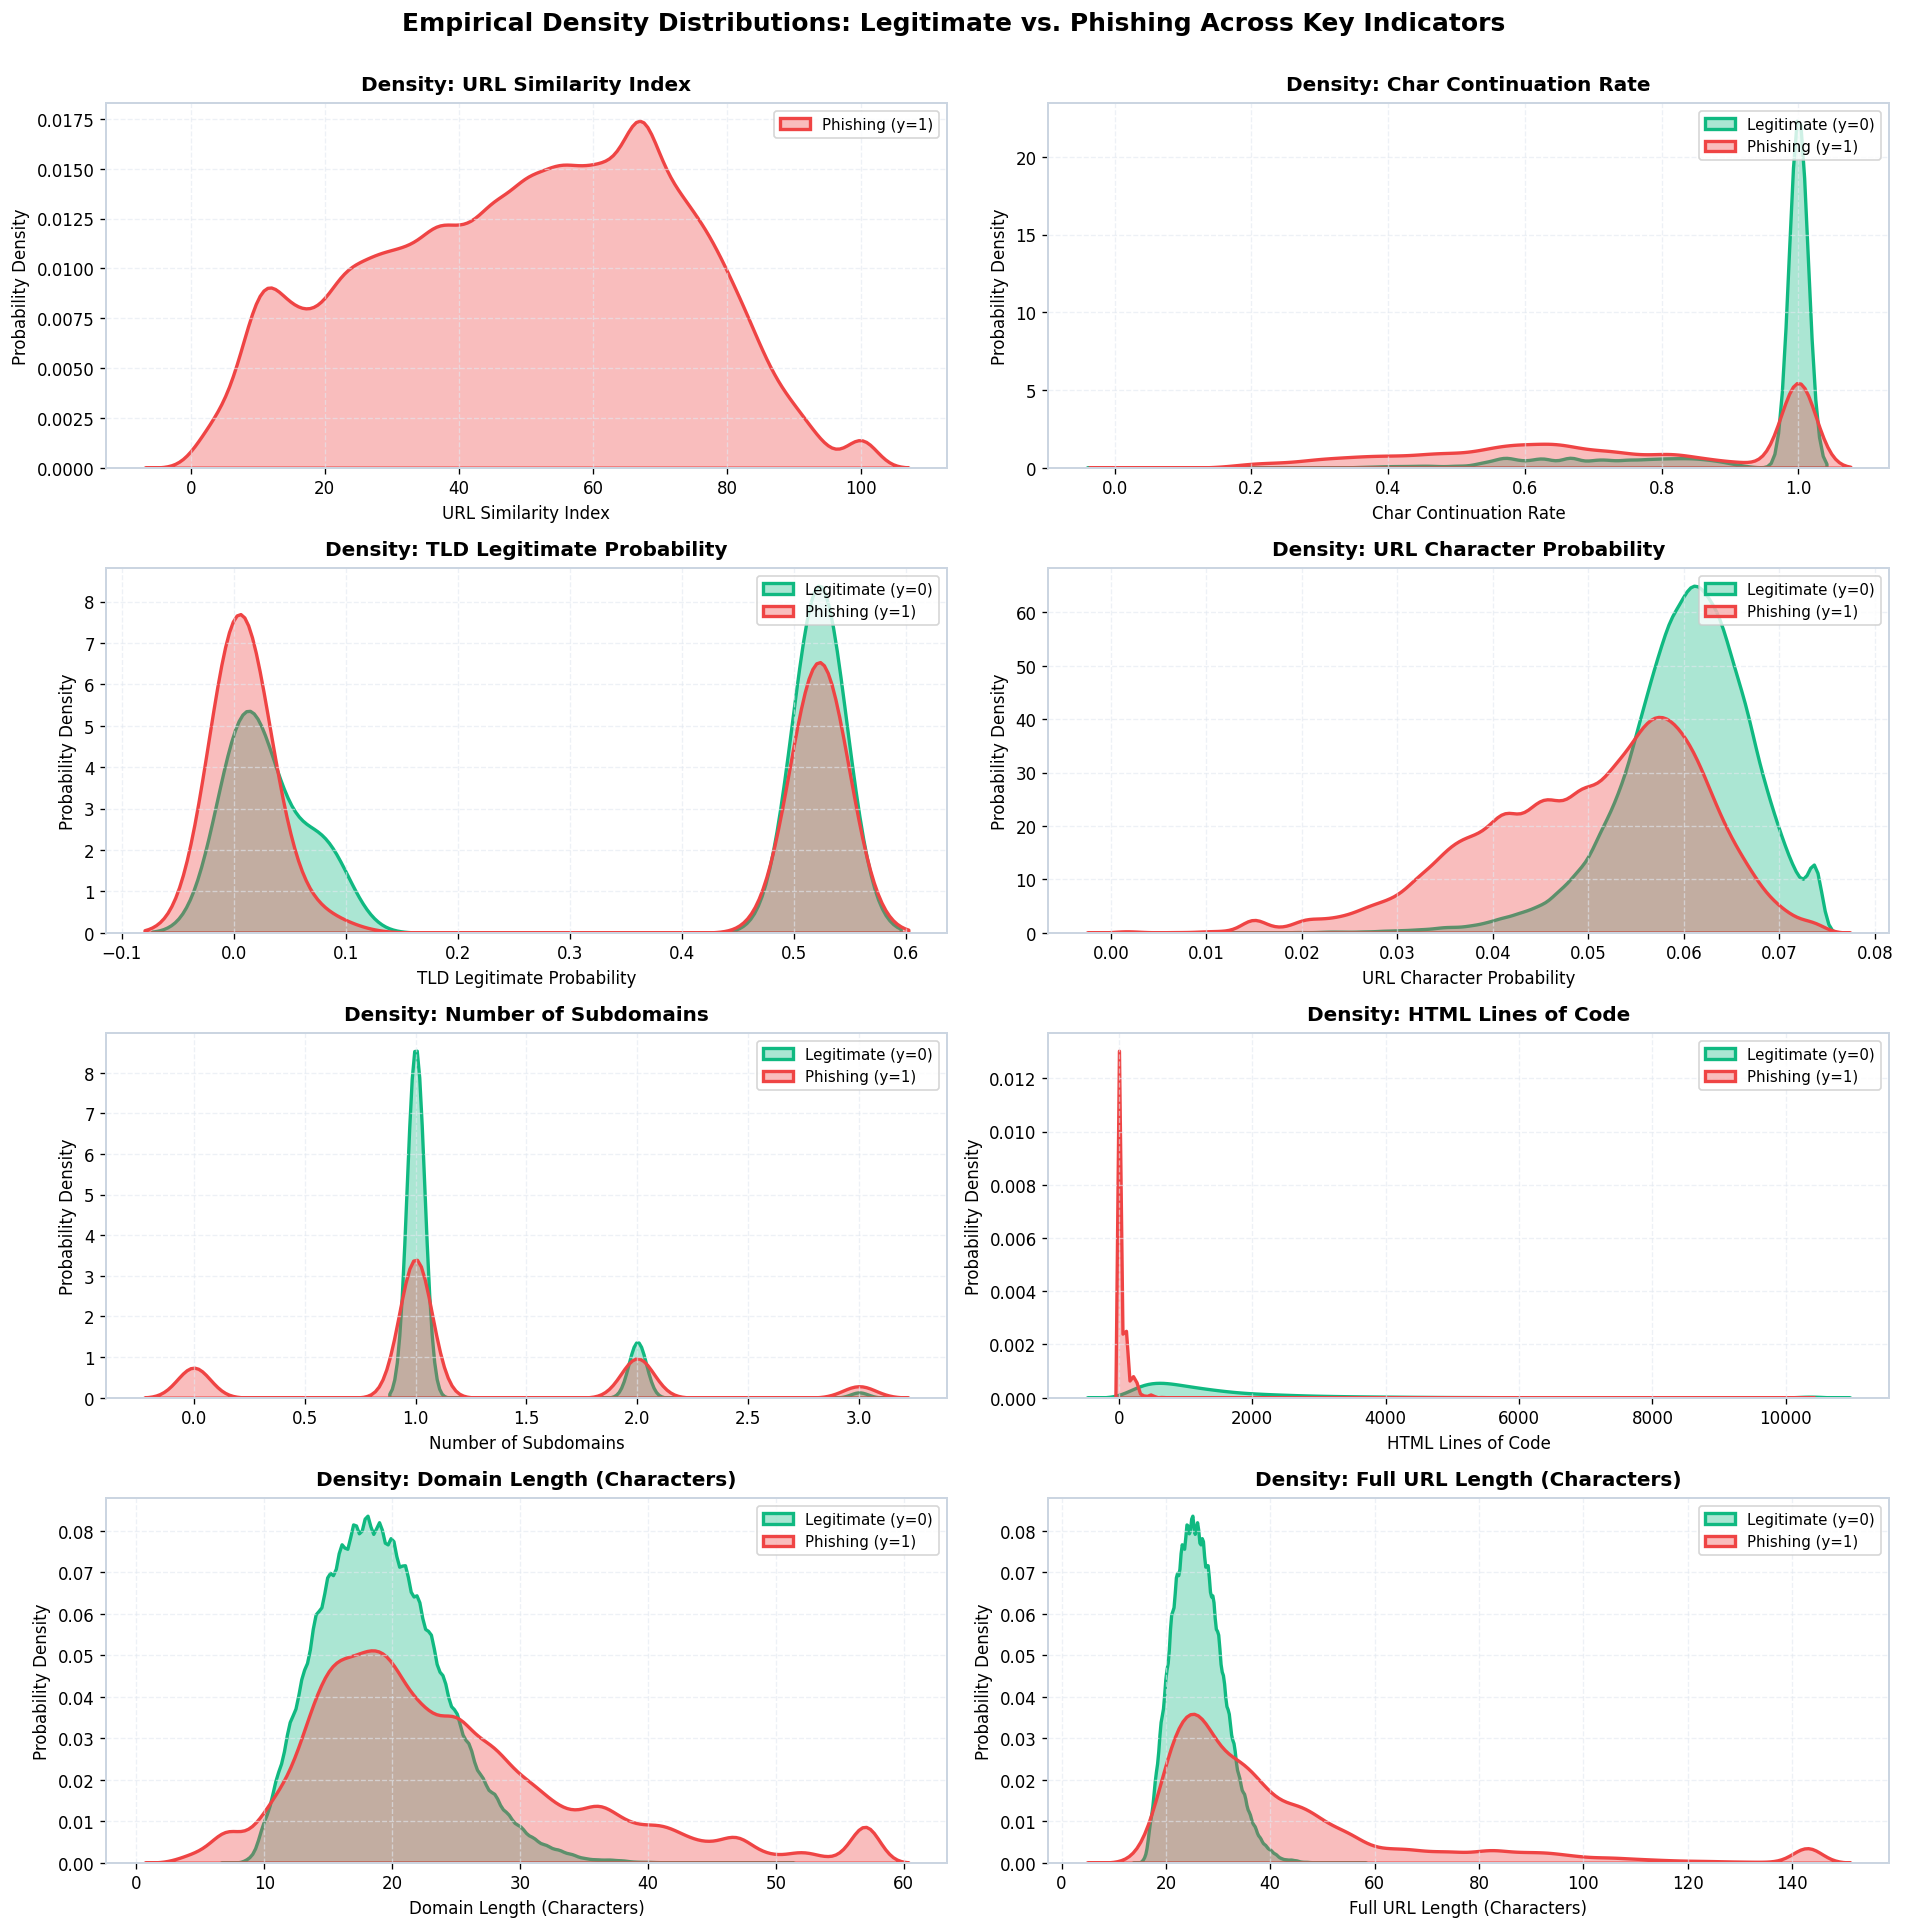

In [6]:
# Figure 2: Empirical Feature Densities by Target Class
key_features = [
    ("URLSimilarityIndex", "URL Similarity Index"),
    ("CharContinuationRate", "Char Continuation Rate"),
    ("TLDLegitimateProb", "TLD Legitimate Probability"),
    ("URLCharProb", "URL Character Probability"),
    ("NoOfSubDomain", "Number of Subdomains"),
    ("LineOfCode", "HTML Lines of Code"),
    ("DomainLength", "Domain Length (Characters)"),
    ("URLLength", "Full URL Length (Characters)")
]

fig, axes = plt.subplots(4, 2, figsize=(16, 16))
axes = axes.flatten()

for idx, (col_name, display_title) in enumerate(key_features):
    ax = axes[idx]
    
    # Clip extreme outliers for visual clarity on long-tailed distributions
    p99 = df[col_name].quantile(0.99)
    p01 = df[col_name].quantile(0.00)
    data_legit = df[df['target'] == 0][col_name].clip(lower=p01, upper=p99)
    data_phish = df[df['target'] == 1][col_name].clip(lower=p01, upper=p99)
    
    # Plot KDE density curves
    sns.kdeplot(data_legit, ax=ax, color='#10B981', fill=True, alpha=0.35, label='Legitimate (y=0)', linewidth=2)
    sns.kdeplot(data_phish, ax=ax, color='#EF4444', fill=True, alpha=0.35, label='Phishing (y=1)', linewidth=2)
    
    ax.set_title(f"Density: {display_title}", fontsize=12, weight='bold', pad=8)
    ax.set_xlabel(display_title, fontsize=10)
    ax.set_ylabel("Probability Density", fontsize=10)
    ax.legend(loc='upper right', frameon=True, fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.6)

plt.suptitle("Empirical Density Distributions: Legitimate vs. Phishing Across Key Indicators", fontsize=15, weight='bold', y=1.002)
plt.tight_layout()
plt.show()

## 7. Inter-Feature Correlation Heatmap

Evaluating multicollinearity and feature interactions is essential for linear models like Logistic Regression. We compute the Pearson correlation matrix for the top 16 most influential features and render an annotated heatmap.

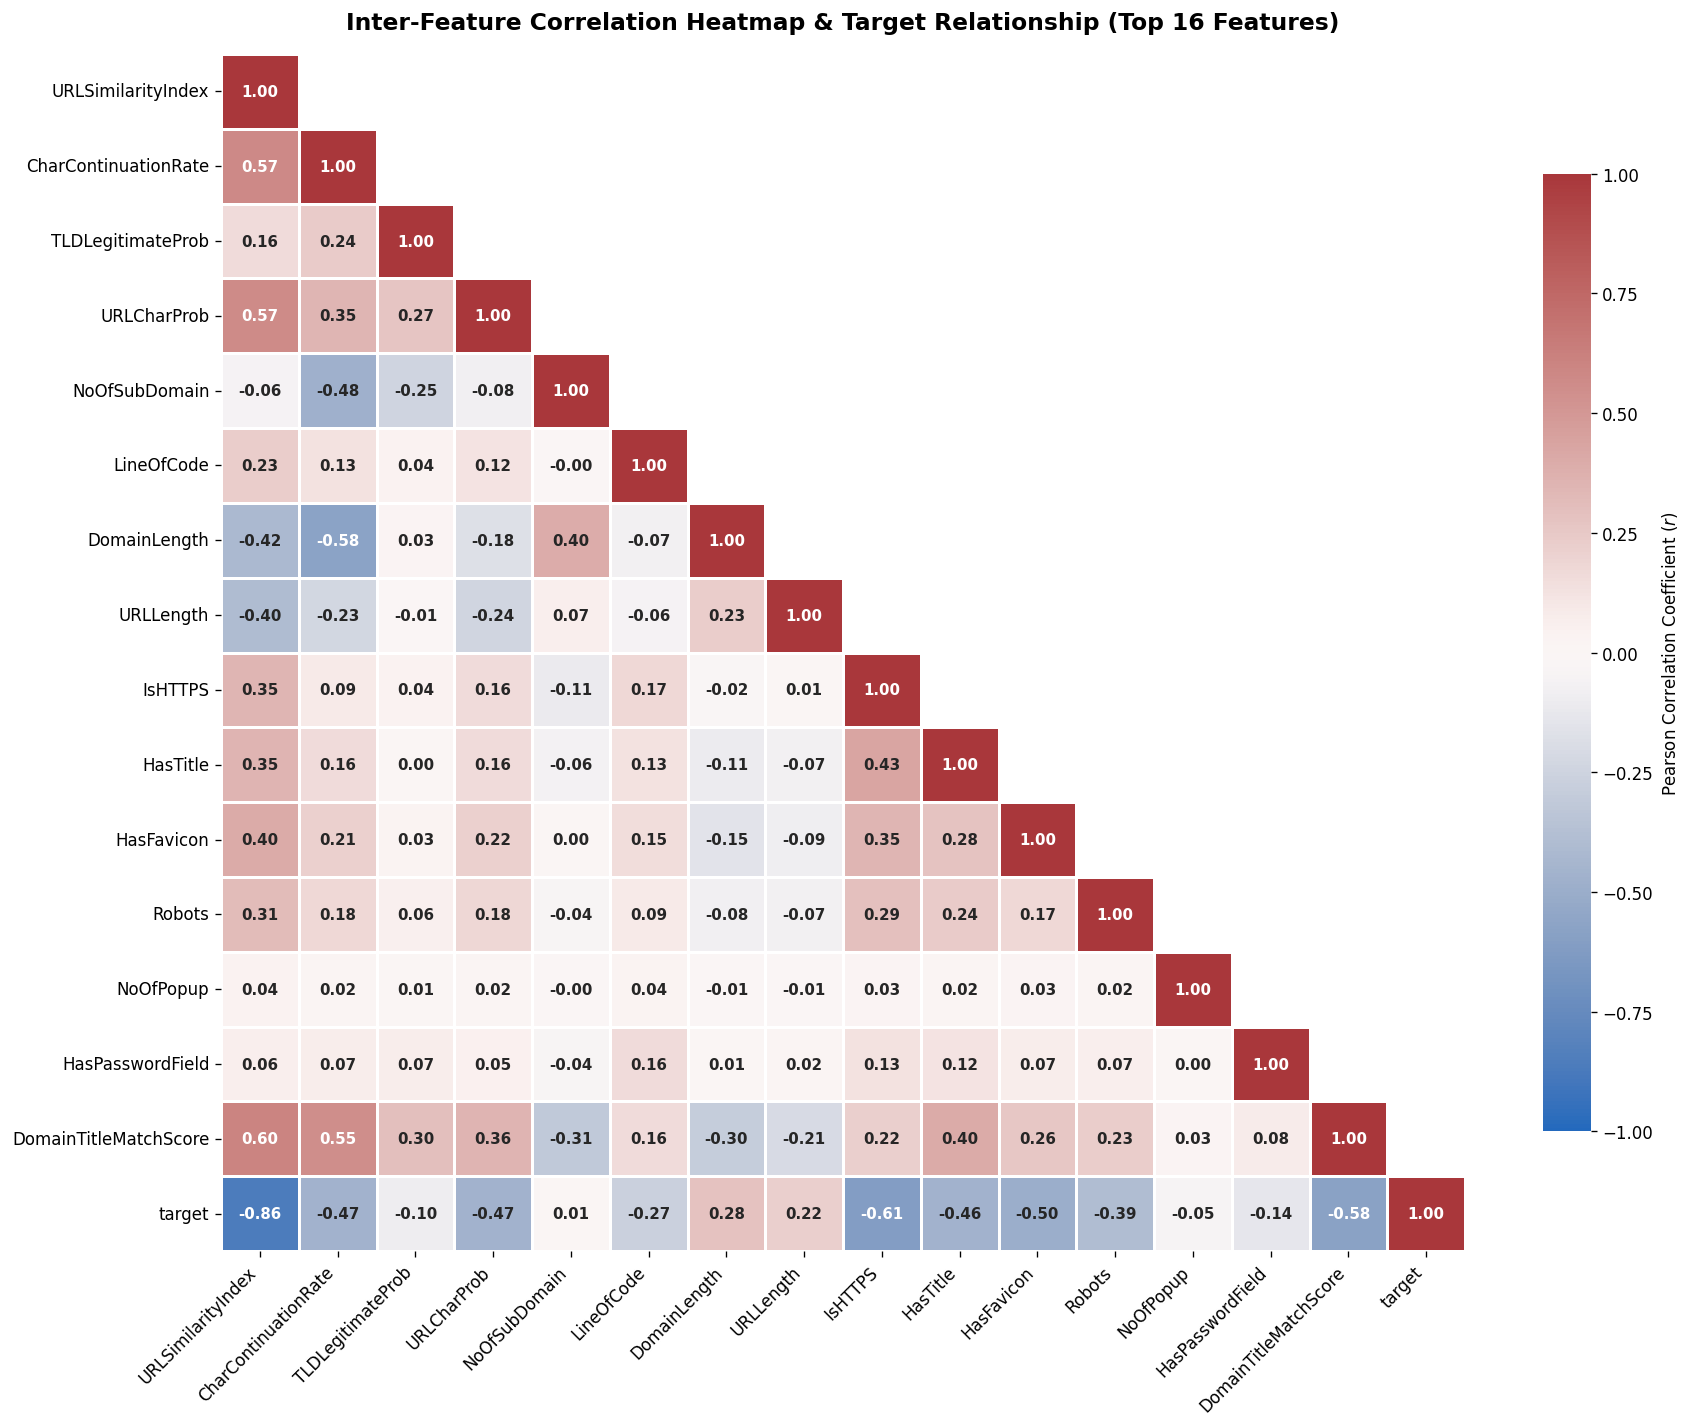

In [7]:
# Figure 3: Correlation Matrix Heatmap
top_corr_features = [
    "URLSimilarityIndex", "CharContinuationRate", "TLDLegitimateProb", "URLCharProb",
    "NoOfSubDomain", "LineOfCode", "DomainLength", "URLLength", "IsHTTPS",
    "HasTitle", "HasFavicon", "Robots", "NoOfPopup", "HasPasswordField",
    "DomainTitleMatchScore", "target"
]

corr_matrix = df[top_corr_features].corr()

plt.figure(figsize=(15, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1.0,
    vmax=1.0,
    center=0,
    linewidths=0.75,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient ($r$)"},
    annot_kws={"size": 9, "weight": "semibold"}
)

plt.title("Inter-Feature Correlation Heatmap & Target Relationship (Top 16 Features)", fontsize=14, weight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

## 8. Target Correlation Divergence Analysis

We quantify the directional Pearson correlation of all 50 features with the `target` label ($1 = \text{Phishing}$), ranking the strongest malicious risk drivers versus benign indicators.

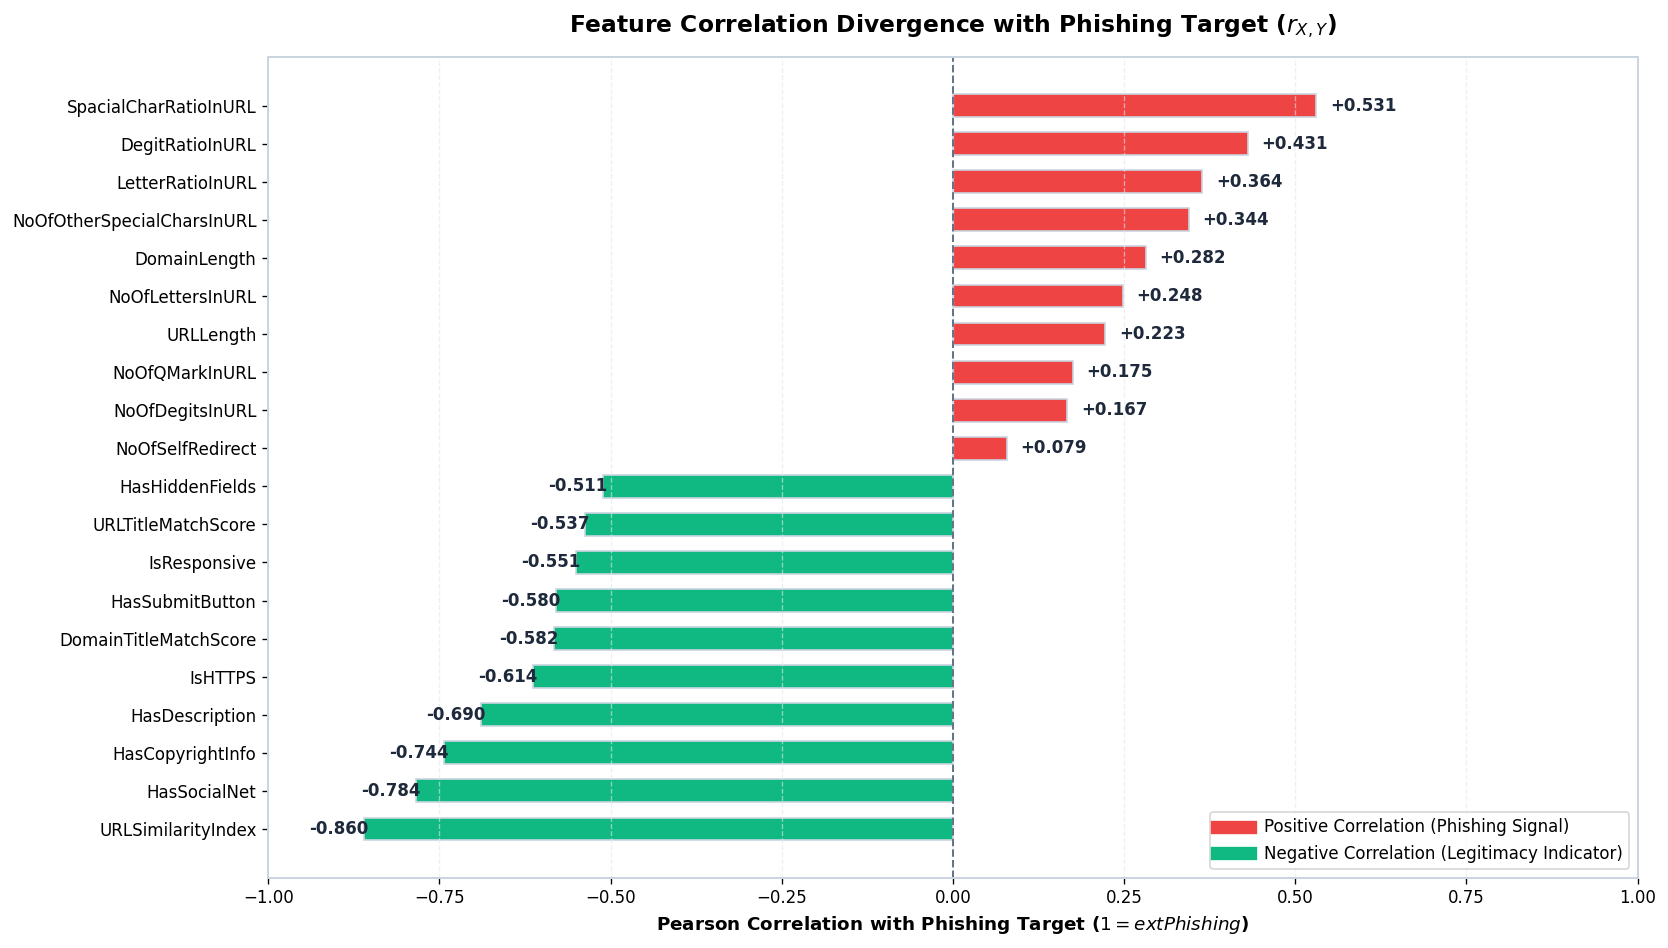

In [8]:
# Figure 4: Top Positively and Negatively Correlated Features with Phishing Target
target_corr = df[feature_cols].apply(lambda x: x.corr(df['target'])).sort_values()

top_negative = target_corr.head(10) # Strongly associated with Legitimate
top_positive = target_corr.tail(10) # Strongly associated with Phishing

corr_divergence = pd.concat([top_negative, top_positive])

plt.figure(figsize=(14, 8))
colors = ['#10B981' if v < 0 else '#EF4444' for v in corr_divergence.values]

bars = plt.barh(corr_divergence.index, corr_divergence.values, color=colors, edgecolor='#CBD5E1', height=0.6)
plt.axvline(x=0, color='#64748B', linestyle='--', linewidth=1.2)
plt.title("Feature Correlation Divergence with Phishing Target ($r_{X, Y}$)", fontsize=14, weight='bold', pad=15)
plt.xlabel("Pearson Correlation with Phishing Target ($1 = \text{Phishing}$)", fontsize=11, weight='bold')
plt.xlim(-1.0, 1.0)
plt.grid(axis='x', linestyle='--', alpha=0.6)

for bar in bars:
    w = bar.get_width()
    offset = 0.02 if w >= 0 else -0.08
    plt.text(w + offset, bar.get_y() + bar.get_height()/2, f"{w:+.3f}",
             va='center', fontsize=10, weight='bold', color='#1E293B')

# Legend
plt.plot([], [], color='#EF4444', label='Positive Correlation (Phishing Signal)', linewidth=8)
plt.plot([], [], color='#10B981', label='Negative Correlation (Legitimacy Indicator)', linewidth=8)
plt.legend(loc='lower right', frameon=True, fontsize=10)

plt.tight_layout()
plt.show()

## 9. Ratio Features & Dispersion Analysis

Obfuscation techniques often manipulate character ratios (digits, letters, special characters). We visualize these distributions using box plots to evaluate spread, median separation, and interquartile ranges.

C:\Users\omgow\AppData\Local\Temp\ipykernel_39100\1824518223.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\omgow\AppData\Local\Temp\ipykernel_39100\1824518223.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Legitimate (0)', 'Phishing (1)'], fontsize=10, weight='bold')


C:\Users\omgow\AppData\Local\Temp\ipykernel_39100\1824518223.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\omgow\AppData\Local\Temp\ipykernel_39100\1824518223.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Legitimate (0)', 'Phishing (1)'], fontsize=10, weight='bold')


C:\Users\omgow\AppData\Local\Temp\ipykernel_39100\1824518223.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\omgow\AppData\Local\Temp\ipykernel_39100\1824518223.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Legitimate (0)', 'Phishing (1)'], fontsize=10, weight='bold')


C:\Users\omgow\AppData\Local\Temp\ipykernel_39100\1824518223.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\omgow\AppData\Local\Temp\ipykernel_39100\1824518223.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Legitimate (0)', 'Phishing (1)'], fontsize=10, weight='bold')


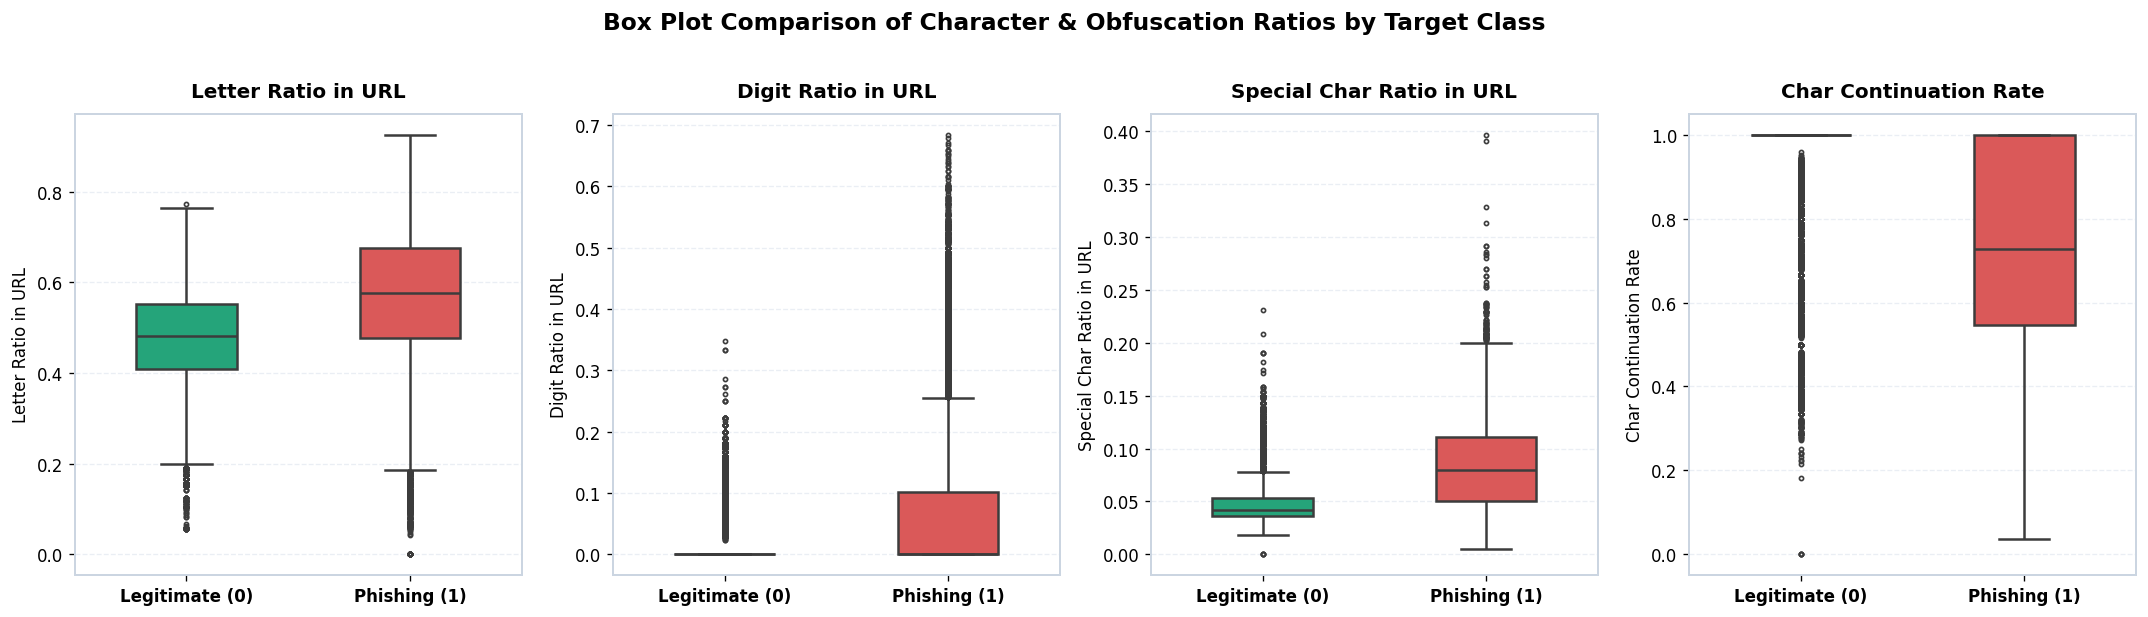

In [9]:
# Figure 5: Box Plot Dispersion of Structural Ratio Features
ratio_cols = [
    ("LetterRatioInURL", "Letter Ratio in URL"),
    ("DegitRatioInURL", "Digit Ratio in URL"),
    ("SpacialCharRatioInURL", "Special Char Ratio in URL"),
    ("CharContinuationRate", "Char Continuation Rate")
]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, (col, title) in enumerate(ratio_cols):
    ax = axes[i]
    sns.boxplot(
        x='target',
        y=col,
        data=df,
        palette=['#10B981', '#EF4444'],
        ax=ax,
        width=0.45,
        fliersize=2.5,
        linewidth=1.5
    )
    ax.set_xticklabels(['Legitimate (0)', 'Phishing (1)'], fontsize=10, weight='bold')
    ax.set_title(title, fontsize=12, weight='bold', pad=10)
    ax.set_xlabel("")
    ax.set_ylabel(title, fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.suptitle("Box Plot Comparison of Character & Obfuscation Ratios by Target Class", fontsize=14, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 10. Statistical Summary Table

To conclude our exploratory data profiling, we generate the comprehensive descriptive statistics table across key predictive features.

In [10]:
# 10. Summary Descriptive Statistics
summary_cols = [
    "URLLength", "DomainLength", "URLSimilarityIndex", "CharContinuationRate",
    "TLDLegitimateProb", "LineOfCode", "NoOfSubDomain", "IsHTTPS"
]

summary_stats = df[summary_cols].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
summary_stats.columns = ['Mean', 'Std Dev', 'Min', 'Q1 (25%)', 'Median', 'Q3 (75%)', 'Max']
print("Descriptive Statistics for Primary Predictive Indicators:")
print(summary_stats.round(3).to_string())

Descriptive Statistics for Primary Predictive Indicators:
                          Mean   Std Dev     Min  Q1 (25%)  Median  Q3 (75%)         Max
URLLength               34.510    43.016  13.000    23.000   27.00    34.000    6097.000
DomainLength            21.456     9.128   4.000    16.000   20.00    24.000     110.000
URLSimilarityIndex      78.539    28.898   0.156    57.312  100.00   100.000     100.000
CharContinuationRate     0.846     0.216   0.000     0.682    1.00     1.000       1.000
TLDLegitimateProb        0.261     0.252   0.000     0.006    0.08     0.523       0.523
LineOfCode            1142.324  3425.115   2.000    17.000  430.00  1277.000  442666.000
NoOfSubDomain            1.165     0.598   0.000     1.000    1.00     1.000      10.000
IsHTTPS                  0.781     0.414   0.000     1.000    1.00     1.000       1.000


## 11. Key EDA Findings & Implications for Machine Learning
1. **Clean Predictive Matrix:** The 50 engineered numerical features are 100% complete with 0 missing values across 191,459 observations.
2. **Balanced Target:** The target variable is naturally distributed (57.3% legitimate vs 42.7% phishing), eliminating the need for aggressive synthetic rebalancing (SMOTE).
3. **Powerful Separators:** Indicators such as `URLSimilarityIndex`, `CharContinuationRate`, `TLDLegitimateProb`, and `LineOfCode` exhibit high divergence between malicious and authentic domains.
4. **Model Architecture Selection:**
   - **Baseline:** Logistic Regression provides an interpretable linear decision boundary.
   - **Improved Models:** Non-linear tree ensembles (Random Forest and XGBoost) can exploit complex feature interactions and non-linear thresholds to minimize False Positives.